##### 2. Asequibilidad
**Una vivienda de 90 m² cuesta 172.226 € en España. ¿Es cara? Depende de lo que gane quien la compra.**

El notebook `01` respondió cuánto cuesta. Este responde la pregunta que de verdad
se hace la gente: **¿cuánto de mi sueldo se lleva?** Y, sobre todo, **¿está
mejorando o empeorando?**

**Tres palabras que van a salir todo el rato**

- **Mediana**: el valor que queda justo en el medio al ordenar. La mitad de las
  provincias están por debajo y la mitad por encima. Se usa en vez de la media
  porque una provincia carísima no la arrastra.
- **Percentil 25 / 75**: el valor que deja por debajo al 25 % / 75 % de las
  provincias. Entre los dos está la mitad central del país.
- **Nominal**: euros de cada año, sin corregir por la inflación. Aquí es a
  propósito: el IPC afectaría igual al precio y a la renta.

**Lo que hay que saber antes de mirar**

- El precio es **valor tasado**, no precio de compraventa.
- La renta es **neta por hogar** (ADRH, INE), no por persona.
- La serie empieza en **2015** porque antes no hay renta provincial, y acaba en
  **2024** porque es el último año publicado. **2025 no se puede calcular**: hay
  precio, pero no renta.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# El import de src/ funciona tanto si Jupyter se lanza desde la raíz del
# proyecto como desde notebooks/.
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (  # noqa: E402
    FIGURES_DIR,
    INCOME_END_YEAR,
    INCOME_START_YEAR,
    NATIONAL_CODE,
    PROCESSED_DIR,
    PROVINCES,
)

plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 150,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Sin dtype, "04" se convierte en 4 y "00" en 0: el cruce por provincia deja
# de casar. Se lee siempre con el código como texto.
panel = pd.read_csv(
    PROCESSED_DIR / "panel_provincia_anual.csv",
    dtype={"province_code": str},
)

# Vivienda total: el mismo agregado que en 01.
total = panel[panel["kind"] == "total"]


##### Bloque 1 · ¿Cuántos años de sueldo cuesta una casa?

**La idea, con algo que no sea una casa.** Un móvil de 6.000 € con un sueldo de
2.000 € al mes cuesta **3 meses de sueldo**. No hace falta saber economía: se
divide el precio entre lo que ganas al mes. Con una vivienda es igual, solo que
el sueldo se mide en años y el precio es el de 90 m²:

`años = (€/m² × 90) ÷ renta neta anual del hogar`

Y la conclusión se lee igual que con el móvil: **cuantos menos años, mejor**.
Cuatro casos reales, con las mismas cuentas:


In [2]:
indexed = total.set_index(["province_code", "year"])

casos = [("13", 2015), ("13", 2024), ("28", 2015), ("28", 2024), (NATIONAL_CODE, 2024)]
rows = []
for code, year in casos:
    row = indexed.loc[(code, year)]
    rows.append({
        "caso": f"{'España' if code == NATIONAL_CODE else PROVINCES[code]} {year}",
        "€/m²": round(float(row["price_nominal_eur_m2"])),
        "piso 90 m²": int(round(row["price_nominal_eur_m2"] * 90)),
        "renta del hogar": int(round(row["net_income_household_eur"])),
        "años": round(float(row["years_90m2"]), 2),
    })

ejemplo = pd.DataFrame(rows).set_index("caso")
display(ejemplo)


,€/m²,piso 90 m²,renta del hogar,años
caso,,,,
Ciudad Real 2015,784,70549,23119,3.05
Ciudad Real 2024,722,64951,33136,1.96
Madrid 2015,2075,186744,37225,5.02
Madrid 2024,3240,291596,51928,5.62
España 2024,1914,172226,40605,4.24


**Leído en voz alta:**

- **Ciudad Real, 2015 → 2024.** El piso de 90 m² pasa de 70.549 € a 64.951 €
  (baja), y la renta del hogar de 23.119 € a 33.136 € (sube mucho más). La
  división pasa de 3,05 a 1,96 años: **mejora**.
- **Madrid, 2015 → 2024.** El piso pasa de 186.744 € a 291.596 € (+56 %) y la
  renta de 37.225 € a 51.928 € (+39 %). El precio corre más que el sueldo: de
  5,02 a 5,62 años. **Empeora.**

Ese es todo el mecanismo: **una división**. Y de ahí sale la primera consecuencia
incómoda: que la vivienda sea más o menos asequible no depende solo de cuánto
sube el precio, sino de si el sueldo sube más o menos que él.


##### La misma cuenta, provincia a provincia

La tabla anterior tiene cinco filas. La gráfica tiene **49 provincias × 10 años**.
Para que quepa en una línea, cada año se resume en tres números:

- **Línea azul: la mediana.** Se ordenan las 49 provincias de menor a mayor
  esfuerzo y se toma la que queda en medio. No es la media: una provincia
  carísima no la arrastra. Si baja, la provincia típica necesita menos años.
- **Banda azul: el 50 % central.** Entre el percentil 25 (deja 12 provincias por
  debajo) y el 75. Si la banda se abre, las provincias se separan; si se
  estrecha, se parecen.
- **Línea roja: España.** No es una provincia ni la media de las 49: es la cifra
  que publica el INE para el conjunto del país, ponderada por el peso de cada
  mercado. Solo existe 2021–2024.

Dos avisos para no leerla al revés:

- **Más abajo es mejor.** El eje son años que hay que pagar, no euros.
- El eje empieza en 2,2, no en cero. En una línea se puede hacer porque marca
  una posición; en una barra, nunca.

**¿Y por qué 49 y no 52?** Porque tres provincias no tienen renta en 2015:
Álava, Gipuzkoa y Navarra. Si se añadieran solo en los años en que existen, la
mediana cambiaría de provincias a mitad de serie y la subida o bajada podría ser
un efecto de quién entra, no del tiempo. Se fija el grupo y se compara siempre lo
mismo.


In [3]:
# El "00" es España, no una provincia: fuera de la serie provincial.
provincial = total[total["province_code"] != NATIONAL_CODE]

# Se fija el panel a las provincias con los diez años completos para que la
# mediana no cambie de composición a mitad de serie.
wide = provincial.pivot(index="province_code", columns="year", values="years_90m2")
years = range(INCOME_START_YEAR, INCOME_END_YEAR + 1)
balanced = wide.loc[:, years].dropna()

serie = pd.DataFrame({
    "p25": balanced.quantile(0.25),
    "mediana": balanced.median(),
    "p75": balanced.quantile(0.75),
})

# España solo existe de 2021 en adelante: el ADRH no publica Total Nacional
# entre 2015 y 2020. Es un hueco del dato, no un cero.
nacional = (
    total.loc[total["province_code"] == NATIONAL_CODE]
    .set_index("year")["years_90m2"]
    .dropna()
)

print(f"Provincias en la serie: {len(balanced)}")
print("Fuera por falta de renta en 2015: "
      + ", ".join(PROVINCES[c] for c in wide.index.difference(balanced.index)))
print(f"España: {int(nacional.index.min())}-{int(nacional.index.max())}")


Provincias en la serie: 49
Fuera por falta de renta en 2015: Araba/Álava, Gipuzkoa, Navarra
España: 2021-2024


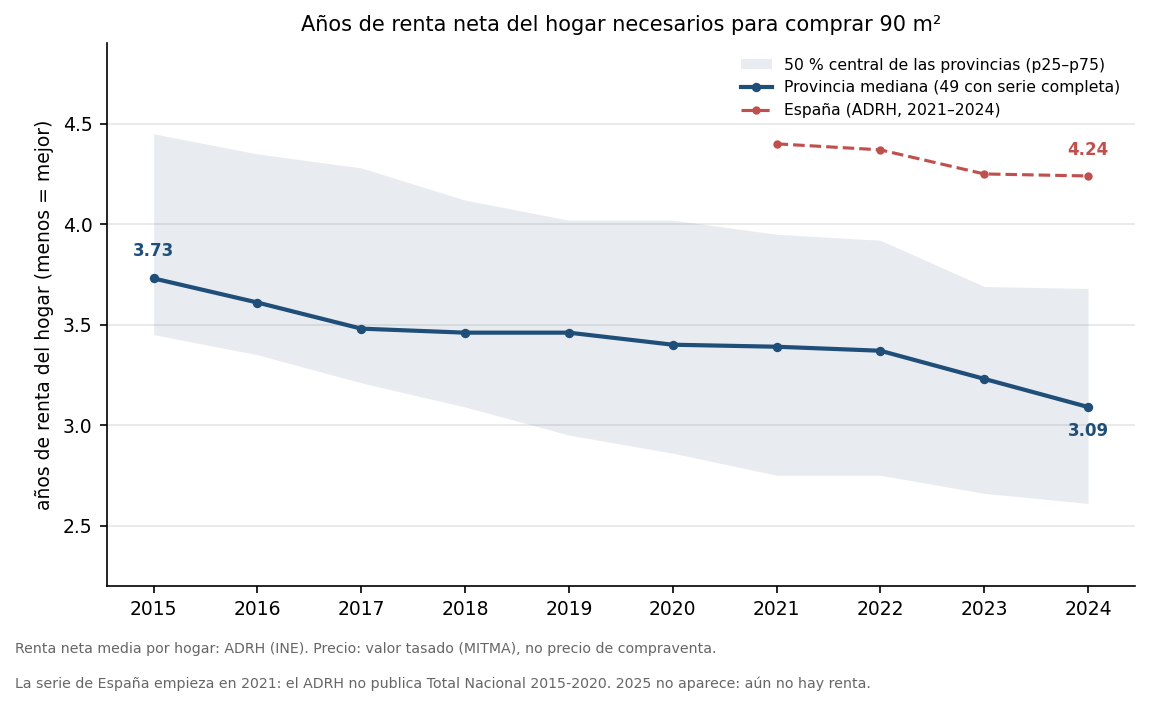

In [4]:
fig, ax = plt.subplots(figsize=(7.6, 4.3))

ax.fill_between(
    serie.index, serie["p25"], serie["p75"],
    color="#1f4e79", alpha=0.10, linewidth=0,
    label="50 % central de las provincias (p25–p75)",
)
ax.plot(
    serie.index, serie["mediana"],
    color="#1f4e79", linewidth=2, marker="o", markersize=3.5,
    label=f"Provincia mediana ({len(balanced)} con serie completa)",
)
ax.plot(
    nacional.index, nacional,
    color="#c0504d", linewidth=1.5, linestyle="--", marker="o", markersize=3,
    label="España (ADRH, 2021–2024)",
)

ax.set_title("Años de renta neta del hogar necesarios para comprar 90 m²")
ax.set_ylabel("años de renta del hogar (menos = mejor)")
ax.set_xticks(list(years))
ax.set_ylim(2.2, 4.9)
ax.grid(axis="y", color="0.9", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper right", fontsize=7.5)

for year, dy in ((2015, 11), (2024, -14)):
    ax.annotate(
        f"{serie.loc[year, 'mediana']:.2f}",
        (year, serie.loc[year, "mediana"]),
        textcoords="offset points", xytext=(0, dy),
        ha="center", fontsize=8, color="#1f4e79", fontweight="bold",
    )

ax.annotate(
    f"{nacional.iloc[-1]:.2f}",
    (nacional.index[-1], nacional.iloc[-1]),
    textcoords="offset points", xytext=(0, 10),
    ha="center", fontsize=8, color="#c0504d", fontweight="bold",
)

fig.text(
    0.0, -0.02,
    "Renta neta media por hogar: ADRH (INE). Precio: valor tasado (MITMA), "
    "no precio de compraventa.",
    fontsize=6.8, color="0.4",
)
fig.text(
    0.0, -0.075,
    "La serie de España empieza en 2021: el ADRH no publica Total Nacional "
    "2015-2020. 2025 no aparece: aún no hay renta.",
    fontsize=6.8, color="0.4",
)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_evolucion.png", bbox_inches="tight")
plt.show()


In [5]:
resumen = serie.loc[[2015, 2021, 2024]].round(2)
resumen.index.name = "año"
display(resumen)

mediana_2015 = serie.loc[2015, "mediana"]
mediana_2024 = serie.loc[2024, "mediana"]

print(f"Mediana 2015: {mediana_2015:.2f} -> 2024: {mediana_2024:.2f} "
      f"({mediana_2024 / mediana_2015 - 1:+.1%})")
print(f"p25: {serie.loc[2015, 'p25']:.2f} -> {serie.loc[2024, 'p25']:.2f} "
      f"({serie.loc[2024, 'p25'] / serie.loc[2015, 'p25'] - 1:+.1%})")
print(f"p75: {serie.loc[2015, 'p75']:.2f} -> {serie.loc[2024, 'p75']:.2f} "
      f"({serie.loc[2024, 'p75'] / serie.loc[2015, 'p75'] - 1:+.1%})")

# La misma ventana para comparar con España, que solo tiene 2021-2024.
print(f"Mediana provincial 2021-2024: {serie.loc[2021, 'mediana']:.2f} -> "
      f"{mediana_2024:.2f} ({mediana_2024 / serie.loc[2021, 'mediana'] - 1:+.1%})")
print(f"España 2021-2024: {nacional.loc[2021]:.2f} -> {nacional.loc[2024]:.2f} "
      f"({nacional.loc[2024] / nacional.loc[2021] - 1:+.1%})")

# La mediana de 2024 con las 52 provincias, para no esconder la diferencia.
todas_2024 = provincial.loc[
    (provincial["year"] == 2024) & provincial["years_90m2"].notna(), "years_90m2"
]
print(f"Mediana 2024 con las {len(todas_2024)} provincias: {todas_2024.median():.2f}")

for year in (2015, 2024):
    values = balanced[year]
    print(f"{year}: p90/p10 {values.quantile(.9) / values.quantile(.1):.2f}x | "
          f"max/min {values.max() / values.min():.2f}x")


,p25,mediana,p75
año,,,
2015,3.45,3.73,4.45
2021,2.75,3.39,3.95
2024,2.61,3.09,3.68


Mediana 2015: 3.73 -> 2024: 3.09 (-17.2%)
p25: 3.45 -> 2.61 (-24.3%)
p75: 4.45 -> 3.68 (-17.3%)
Mediana provincial 2021-2024: 3.39 -> 3.09 (-8.8%)
España 2021-2024: 4.40 -> 4.24 (-3.6%)
Mediana 2024 con las 52 provincias: 3.24
2015: p90/p10 1.56x | max/min 2.34x
2024: p90/p10 1.92x | max/min 3.10x


##### Lo que dicen los datos

**¿Qué muestra la línea azul, en una frase?**
Los años de renta que necesita la provincia que queda en medio de las 49. En 2015
eran **3,73** (casi cuatro años de sueldo entero); en 2024, **3,09** (tres años y
un mes).

**¿3,09 años es mucho o poco?**
Mucho. Significa dedicar **tres años enteros de todo lo que ingresa el hogar** a
pagar la casa, sin comer, sin luz y sin colegio. Si se destinara a la vivienda el
30 % de la renta —la proporción que suele considerarse razonable—, harían falta
unos **10,3 años** para cubrir el precio, y eso sin contar intereses. En Madrid
(5,62) serían **18,7 años**; en Ciudad Real (1,96), 6,5.

**¿Ha mejorado o empeorado desde 2015?**
Mejorado: de **3,73 a 3,09 años (−17,2 %)**. Es la diferencia entre deber casi
cuatro años de sueldo y deber tres.

**Pero si los precios han subido, ¿cómo puede mejorar?**
Porque la renta subió mucho más. Entre 2015 y 2024, en esas mismas 49 provincias,
el precio nominal mediano subió un **13,0 %** y la renta neta mediana del hogar,
un **41,1 %**. La mejora no la hizo el ladrillo: la hizo el sueldo.

Y hay una trampa de lectura: **2015 es el peor año de la serie** (3,73). Si se
compara 2024 con 2021, la mejora es del 8,8 %, no del 17,2 %. El punto de partida
elegido cambia el titular, y conviene decirlo.

**¿Mejora en todas partes?**
No. **45 de las 49 provincias mejoran y 4 empeoran**: Madrid (+12,0 %), Baleares
(+5,5 %), Málaga (+3,8 %) y Barcelona (+1,8 %). Son justo las cuatro donde el
precio creció más que la renta. Eso es el bloque 3.

**¿Por qué la línea de España va por encima y baja menos?**
En 2021, España marca 4,40 y la provincia mediana 3,39. No es un error: la cifra
nacional está **ponderada por el mercado**, así que pesa mucho Madrid, Barcelona
y Baleares, que son caras. Es la misma historia que en el `01` con 2.128 frente a
1.421. Por eso, entre 2021 y 2024, la mediana provincial cae un **8,8 %** y
España solo un **3,6 %**: las provincias que empeoran son las que más pesan en el
total nacional.

**¿Y la banda azul?**
Es la prueba de que el país se separa. El percentil 25 cae un **24,3 %** y el 75
solo un **17,3 %**: las provincias baratas mejoran más rápido que las caras. El
máximo dividido entre el mínimo pasa de **2,3 a 3,1 veces**, y el p90/p10, de 1,6
a 1,9. La media mejora y la brecha se abre.

**¿Y 2025?**
El precio subió un **11,2 % nominal** y no hay renta publicada. Si la renta
creciera al ritmo del periodo (3,9 % anual), el esfuerzo subiría cerca de un 7 %
en un solo año. Es una estimación, no un dato, pero sirve para no leer esta
gráfica como si siguiera viva: **la serie termina justo cuando venía mejorando**.

**¿Qué no dice este bloque?**

- No dice el precio de compraventa: es **valor tasado**.
- No dice si puedes pagar una hipoteca: no hay tipos, entrada ni plazo.
- No dice nada de **2007–2014**: no hay renta provincial.
- El nivel exacto depende de las 49: con las 52 provincias, la mediana de 2024
  es **3,24**, no 3,09. La serie usa 49 para que el cambio sea comparable.
- La «provincia mediana» no es donde vive la persona mediana: Madrid y Barcelona
  concentran mucha más población que su peso en el conteo de provincias.

**Entonces, ¿cuál es el problema?**
Que la vivienda en España no es un problema único, sino dos. En la mayoría del
país el acceso **mejoró** entre 2015 y 2024 porque los sueldos subieron más que
los precios. En Madrid, Baleares, Málaga y Barcelona ocurrió lo contrario, y son
las zonas donde más gente quiere vivir y donde más pesa el mercado. El resultado
no es un país más caro: es un país **más desigual**, con una brecha que pasó de
2,3 a 3,1 veces. Y en 2025 el precio vuelve a subir sin que sepamos si la renta
lo acompaña.

En el bloque 2 ponemos esto en el mapa: **¿dónde duele?**


##### Bloque 2 · ¿Dónde duele?

El bloque 1 dio la cifra del país. El mapa da la otra mitad de la historia: **el
mismo año, provincia a provincia**.

Cómo se lee un mapa así (se llama **coroplético**):

- **El color es el esfuerzo**: años de renta del hogar para pagar 90 m² en 2024.
  Más oscuro, más años.
- **La escala es única** para la península y para el recuadro de Canarias. Si
  cada una tuviera la suya, el archipiélago podría parecer igual de caro que
  Madrid sin serlo.
- **El tamaño de la mancha no significa nada**: Badajoz ocupa mucho y pesa poco;
  Madrid es pequeña y concentra el problema. El mapa da protagonismo a la
  superficie, no a la población.
- **Se lee por extremos y por masa**: dónde están los más oscuros, dónde los más
  claros y dónde está el grueso.

Cinco tramos de color, para poder nombrar el color sin interpretar un degradado.


In [6]:
import geopandas as gpd

mapa = gpd.read_file(PROCESSED_DIR / "provincias.geojson")  # una columna es la geometría

effort_2024 = total.loc[
    (total["year"] == 2024) & (total["province_code"] != NATIONAL_CODE),
    ["province_code", "years_90m2"],
]

mapa = mapa.merge(effort_2024, on="province_code", how="left", validate="one_to_one")

print(f"Provincias en el mapa: {len(mapa)}")
print(f"Sin esfuerzo: {mapa['years_90m2'].isna().sum()}")
print(f"Rango: {mapa['years_90m2'].min():.2f} - {mapa['years_90m2'].max():.2f} años")

# El total nacional como numero suelto, para comparar con el mapa.
national_2024 = total.loc[
    (total["province_code"] == NATIONAL_CODE) & (total["year"] == 2024),
    "years_90m2",
].iloc[0]
print(f"España 2024: {national_2024:.2f} años")


Provincias en el mapa: 52
Sin esfuerzo: 0
Rango: 1.96 - 6.08 años
España 2024: 4.24 años


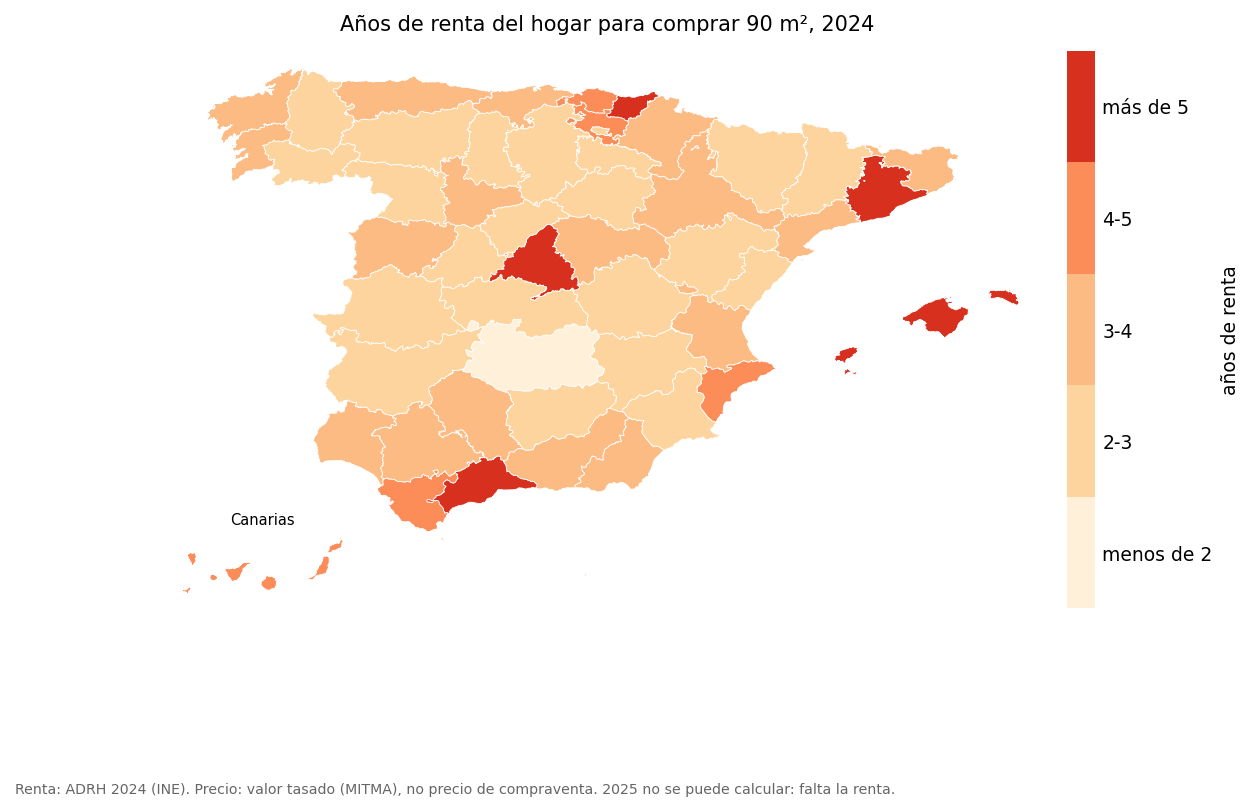

In [7]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import BoundaryNorm, ListedColormap

CANARIAS = ["35", "38"]

# Cinco tramos. La distribucion se concentra entre 2 y 4 anos (40 de 52
# provincias), asi que un degradado continuo dejaria medio pais del mismo tono.
bounds = [0, 2, 3, 4, 5, 7]
colors = ["#fef0d9", "#fdd49e", "#fdbb84", "#fc8d59", "#d7301f"]
cmap = ListedColormap(colors)
norm = BoundaryNorm(bounds, cmap.N)

fig, ax = plt.subplots(figsize=(8, 6))

mapa[~mapa["province_code"].isin(CANARIAS)].plot(
    ax=ax,
    column="years_90m2",
    cmap=cmap,
    norm=norm,
    edgecolor="white",
    linewidth=0.4,
)

ax.set_xlim(-10.0, 4.8)
ax.set_ylim(34.6, 44.2)
ax.set_aspect("equal")
ax.set_axis_off()
ax.set_title("Años de renta del hogar para comprar 90 m², 2024")

ax_can = ax.inset_axes([0.01, 0.0, 0.20, 0.18])
mapa[mapa["province_code"].isin(CANARIAS)].plot(
    ax=ax_can,
    column="years_90m2",
    cmap=cmap,
    norm=norm,
    edgecolor="white",
    linewidth=0.4,
)
ax_can.set_xlim(-18.4, -13.2)
ax_can.set_ylim(27.4, 29.6)
ax_can.set_aspect("equal")
ax_can.set_axis_off()
ax_can.set_title("Canarias", fontsize=7, pad=1)

colorbar = fig.colorbar(
    ScalarMappable(norm=norm, cmap=cmap),
    ax=ax,
    fraction=0.03,
    pad=0.02,
    spacing="uniform",
    ticks=[1, 2.5, 3.5, 4.5, 6],
)
colorbar.ax.set_yticklabels(["menos de 2", "2-3", "3-4", "4-5", "más de 5"])
colorbar.ax.tick_params(which="both", length=0)
colorbar.set_label("años de renta")
colorbar.outline.set_visible(False)

fig.text(
    0.0, -0.02,
    "Renta: ADRH 2024 (INE). Precio: valor tasado (MITMA), no precio de "
    "compraventa. 2025 no se puede calcular: falta la renta.",
    fontsize=6.8, color="0.4",
)

fig.savefig(FIGURES_DIR / "02_mapa_2024.png", dpi=150, bbox_inches="tight")
plt.show()


In [8]:
# El reparto que la leyenda resume en colores.
tramos = pd.cut(
    mapa["years_90m2"], [0, 2, 3, 4, 5, 7],
    labels=["menos de 2", "2-3", "3-4", "4-5", "más de 5"],
)
print(tramos.value_counts().sort_index().rename("provincias").to_frame().to_string())

print(f"\nPor encima de España ({national_2024:.2f}): "
      f"{(mapa['years_90m2'] > national_2024).sum()} provincias")

top = mapa.nlargest(5, "years_90m2").assign(
    nombre=lambda df: df["province_code"].map(PROVINCES)
)
print("\nLas cinco que más duelen:")
print(top[["nombre", "years_90m2"]].round(2).to_string(index=False))

# Precio y esfuerzo no ordenan igual: el salto entre puestos lo explica la renta.
gap = (
    total.loc[
        (total["year"] == 2024) & (total["province_code"] != NATIONAL_CODE),
        ["province_code", "price_nominal_eur_m2", "years_90m2"],
    ]
    .assign(
        nombre=lambda df: df["province_code"].map(PROVINCES),
        puesto_precio=lambda df: df["price_nominal_eur_m2"].rank(ascending=False).astype(int),
        puesto_esfuerzo=lambda df: df["years_90m2"].rank(ascending=False).astype(int),
    )
)
gap["salto"] = gap["puesto_esfuerzo"] - gap["puesto_precio"]

# Los casos citados en el texto, comprobados uno a uno.
casos = ["18", "06", "11", "03", "31", "42"]
print("\nEl precio no ordena igual que el esfuerzo:")
print(
    gap.loc[gap["province_code"].isin(casos),
            ["nombre", "puesto_precio", "puesto_esfuerzo", "salto"]]
    .sort_values("salto")
    .to_string(index=False)
)


            provincias
years_90m2            
menos de 2           1
2-3                 21
3-4                 19
4-5                  6
más de 5             5

Por encima de España (4.24): 10 provincias

Las cinco que más duelen:
       nombre  years_90m2
       Málaga        6.08
Illes Balears        5.97
       Madrid        5.62
     Gipuzkoa        5.43
    Barcelona        5.20

El precio no ordena igual que el esfuerzo:
          nombre  puesto_precio  puesto_esfuerzo  salto
         Granada             26               16    -10
         Badajoz             45               37     -8
Alicante/Alacant             16                9     -7
           Cádiz             15                8     -7
           Soria             41               49      8
         Navarra             14               26     12


##### Lo que dice el mapa

**¿Qué se ve a primera vista?**
Que el problema no está repartido. **Cinco provincias pasan de cinco años**:
Málaga (6,08), Baleares (5,97), Madrid (5,62), Gipuzkoa (5,43) y Barcelona
(5,20). Y **diez superan la media nacional** (4,24): las cinco anteriores más
Bizkaia (4,84), Álava (4,36), Cádiz (4,34), Alicante (4,31) y Tenerife (4,28).

**Pero el grueso del país está por debajo de cuatro años.**
**41 de las 52 provincias** no llegan a cuatro años, y **22 no llegan a tres**.
Solo una baja de dos: Ciudad Real (1,96). El mapa impresiona por los extremos;
la mayoría del país está en los tonos claros.

**¿Es el mismo mapa que el del precio?**
Casi: la correlación entre precio y esfuerzo es **0,95**. Pero las diferencias son
justo la información.

- **Málaga es la 6.ª en precio y la 1.ª en esfuerzo.** No es la más cara, pero es
  la que más duele: su renta (35.844 €) está muy por debajo de la de Madrid
  (51.928 €) con un precio parecido.
- **Cádiz y Alicante** son la 15.ª y la 16.ª en precio, pero la 8.ª y la 9.ª en
  esfuerzo. Costeras con rentas de 33.000–34.000 €.
- **Granada** es la 26.ª en precio y la 16.ª en esfuerzo: barata de escaparate,
  cara de pagar.
- Al revés, **Navarra** es la 14.ª en precio y la 26.ª en esfuerzo (renta de
  45.453 €), y **Soria**, con 962 €/m², tiene el cuarto esfuerzo más bajo porque
  su renta (37.887 €) es alta para lo que cuesta la vivienda.

**¿Qué significa todo eso?**
Que hay **dos formas distintas de que la vivienda duela**: que sea cara (Madrid,
Baleares, Gipuzkoa, Barcelona) o que la renta sea baja (Málaga, Cádiz, Alicante,
Granada). El mapa pinta las dos del mismo color, y separarlas es el bloque 3.

**¿Y Canarias?**
Tenerife (4,28) y Las Palmas (4,23) quedan justo a la altura de la media nacional
(4,24), una por encima y otra por debajo. Sus precios no son de los más altos
(1.806 y 1.858 €/m²), pero sus rentas tampoco (37.980 y 39.533 €).

**¿Qué no dice el mapa?**

- **Superficie no es población**: una provincia grande y despoblada ocupa mucho
  y pesa poco. Dice dónde, no cuánta gente lo sufre.
- **Provincia no es ciudad**: dentro de Málaga conviven la costa y el interior, y
  el dato las mezcla.
- Es **valor tasado**, no precio de compraventa.
- Es **2024**, no 2025: el mapa del `01` es de 2025 porque el precio existe, pero
  aquí hace falta la renta, y la última publicada es 2024.
- El color es una **media provincial**: dentro de cada mancha hay mucha variación.

**Entonces, ¿dónde duele?**
En Madrid, el eje Barcelona–Bilbao–Gipuzkoa–Álava, Baleares, Málaga, Cádiz,
Alicante y Canarias. El mapa responde **dónde**, pero no **por qué**. Para eso
hay que separar las dos causas —precio alto y renta baja—, y eso es el bloque 3.


##### Bloque 3 · ¿Por qué mejoran 45 y empeoran 4?

El mapa dijo **dónde**. Este bloque dice **por qué**, y la respuesta sale de una
división:

`esfuerzo = (precio × 90) ÷ renta`

Si la renta sube más que el precio, el esfuerzo baja. Si el precio sube más que la
renta, sube. Cada punto de la gráfica es una provincia:

- **Eje X**: cuánto subió el precio entre 2015 y 2024.
- **Eje Y**: cuánto subió la renta neta del hogar.
- **La diagonal** es el empate: precio y renta subieron lo mismo y el esfuerzo no
  cambió.
- **Por encima**: la renta ganó y el esfuerzo bajó. **Por debajo**: el precio ganó
  y el esfuerzo subió.

Cuanto más lejos de la diagonal está un punto, mayor es el cambio de esfuerzo.


In [9]:
# Cambios 2015->2024 en las 49 provincias con renta en ambos anos.
prov = total[total["province_code"] != NATIONAL_CODE]
piv_price = prov.pivot(index="province_code", columns="year", values="price_nominal_eur_m2")
piv_income = prov.pivot(index="province_code", columns="year", values="net_income_household_eur")
piv_years = prov.pivot(index="province_code", columns="year", values="years_90m2")

paired = piv_years[[INCOME_START_YEAR, INCOME_END_YEAR]].dropna().index

cambios = pd.DataFrame({
    "nombre": [PROVINCES[c] for c in paired],
    "precio": (piv_price.loc[paired, INCOME_END_YEAR]
               / piv_price.loc[paired, INCOME_START_YEAR] - 1) * 100,
    "renta": (piv_income.loc[paired, INCOME_END_YEAR]
              / piv_income.loc[paired, INCOME_START_YEAR] - 1) * 100,
    "esfuerzo": (piv_years.loc[paired, INCOME_END_YEAR]
                 / piv_years.loc[paired, INCOME_START_YEAR] - 1) * 100,
}, index=paired)

# La diagonal no es decorativa: si la renta sube mas que el precio, el esfuerzo
# baja. Es la condicion que separa los dos grupos.
cambios["mejora"] = cambios["renta"] > cambios["precio"]

print(f"Provincias: {len(cambios)}")
print(f"Mejoran (renta > precio): {cambios['mejora'].sum()}")
print(f"Empeoran (precio > renta): {(~cambios['mejora']).sum()}")


Provincias: 49
Mejoran (renta > precio): 45
Empeoran (precio > renta): 4


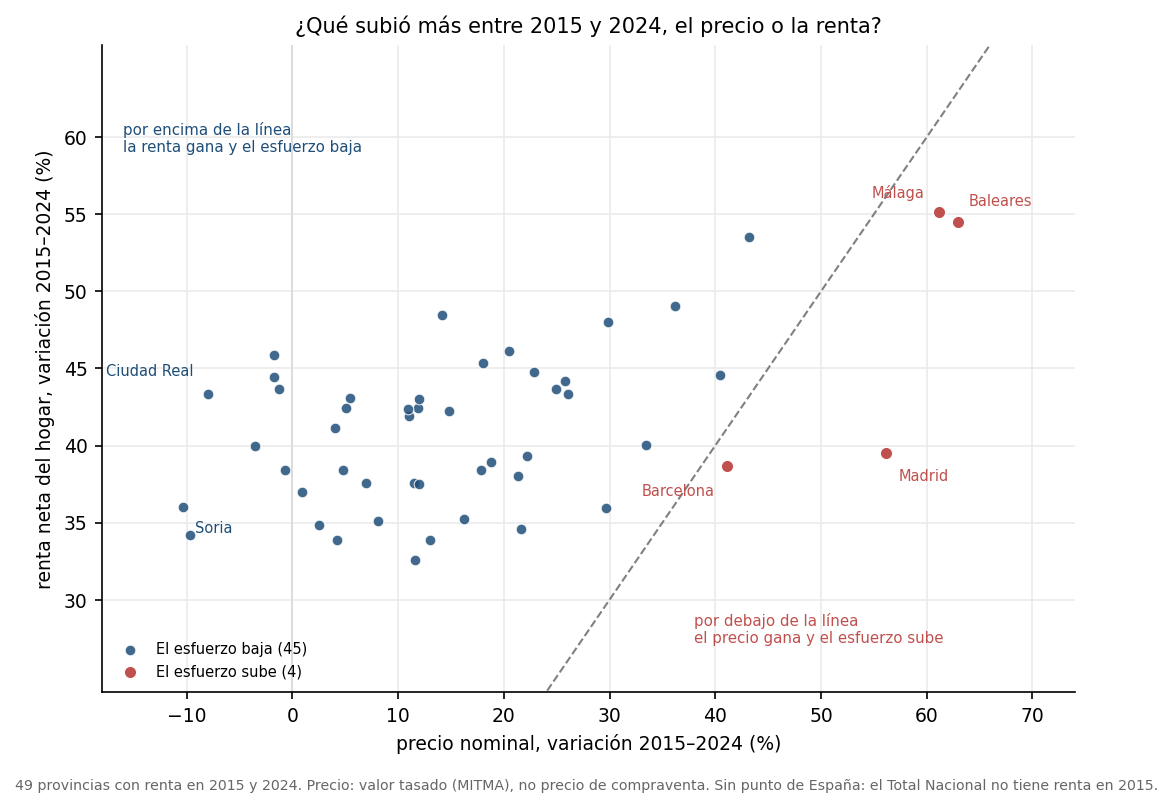

In [10]:
fig, ax = plt.subplots(figsize=(7.2, 5.2))

mejoran = cambios[cambios["mejora"]]
empeoran = cambios[~cambios["mejora"]]

ax.scatter(
    mejoran["precio"], mejoran["renta"],
    s=26, color="#1f4e79", alpha=0.85, edgecolor="white", linewidth=0.5,
    label=f"El esfuerzo baja ({len(mejoran)})",
)
ax.scatter(
    empeoran["precio"], empeoran["renta"],
    s=34, color="#c0504d", edgecolor="white", linewidth=0.5,
    label=f"El esfuerzo sube ({len(empeoran)})",
)

# Diagonal del empate: precio y renta suben lo mismo.
ax.plot([-20, 75], [-20, 75], color="0.5", linestyle="--", linewidth=1)

ax.text(
    -16, 61, "por encima de la línea\nla renta gana y el esfuerzo baja",
    fontsize=7.2, color="#1f4e79", va="top",
)
ax.text(
    38, 27, "por debajo de la línea\nel precio gana y el esfuerzo sube",
    fontsize=7.2, color="#c0504d", va="bottom",
)

# Solo los extremos: con 49 puntos, etiquetar todo es ilegible.
etiquetas = {
    "28": ("Madrid", 6, -13, "left"),
    "08": ("Barcelona", -6, -14, "right"),
    "29": ("Málaga", -7, 7, "right"),
    "07": ("Baleares", 5, 8, "left"),
    "13": ("Ciudad Real", -7, 9, "right"),
    "42": ("Soria", 6, -12, "left"),
}
for code, (name, dx, dy, ha) in etiquetas.items():
    row = cambios.loc[code]
    color = "#c0504d" if not row["mejora"] else "#1f4e79"
    ax.annotate(
        name, (row["precio"], row["renta"]),
        textcoords="offset points", xytext=(dx, dy),
        ha=ha, fontsize=7, color=color,
    )

ax.axvline(0, color="0.85", linewidth=0.8)
ax.set_xlim(-18, 74)
ax.set_ylim(24, 66)
ax.set_xticks(range(-10, 71, 10))
ax.set_yticks(range(30, 61, 5))
ax.set_xlabel("precio nominal, variación 2015–2024 (%)")
ax.set_ylabel("renta neta del hogar, variación 2015–2024 (%)")
ax.set_title("¿Qué subió más entre 2015 y 2024, el precio o la renta?")
ax.grid(color="0.92", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower left", fontsize=7)

fig.text(
    0.0, -0.02,
    "49 provincias con renta en 2015 y 2024. Precio: valor tasado (MITMA), no "
    "precio de compraventa. Sin punto de España: el Total Nacional no tiene "
    "renta en 2015.",
    fontsize=6.8, color="0.4",
)

fig.tight_layout()
fig.savefig(FIGURES_DIR / "02_precio_renta.png", bbox_inches="tight")
plt.show()


In [11]:
# Los dos grupos, resumidos: la tabla que explica el grafico.
grupos = cambios.groupby("mejora").agg(
    provincias=("precio", "size"),
    precio=("precio", "median"),
    renta=("renta", "median"),
    esfuerzo=("esfuerzo", "median"),
)
grupos.index = ["Empeoran", "Mejoran"]
display(grupos.round(1))

print(f"Precio: mediana {cambios['precio'].median():+.1f} % | "
      f"desviación típica {cambios['precio'].std():.1f} puntos")
print(f"Renta:  mediana {cambios['renta'].median():+.1f} % | "
      f"desviación típica {cambios['renta'].std():.1f} puntos")
print(f"Provincias con precio negativo: {(cambios['precio'] < 0).sum()}")

print("\nLas cuatro que empeoran:")
print(
    cambios.loc[~cambios["mejora"], ["nombre", "precio", "renta", "esfuerzo"]]
    .sort_values("esfuerzo", ascending=False).round(1).to_string(index=False)
)

print("\nLas cinco que más mejoran:")
print(
    cambios.nsmallest(5, "esfuerzo")[["nombre", "precio", "renta", "esfuerzo"]]
    .round(1).to_string(index=False)
)

# Cuanto de la subida nominal se comio la inflacion, con el deflactor del panel.
nacional = total[total["province_code"] == NATIONAL_CODE].set_index("year")
deflactor = nacional["price_real_eur_m2"] / nacional["price_nominal_eur_m2"]
inflacion = deflactor.loc[INCOME_START_YEAR] / deflactor.loc[INCOME_END_YEAR]

print(f"\nIPC {INCOME_START_YEAR}-{INCOME_END_YEAR}: {inflacion - 1:+.1%}")
print(f"Precio real: {(1 + cambios['precio'].median() / 100) / inflacion - 1:+.1%}")
print(f"Renta real:  {(1 + cambios['renta'].median() / 100) / inflacion - 1:+.1%}")


,provincias,precio,renta,esfuerzo
Empeoran,4,58.6,47.0,4.6
Mejoran,45,12.0,41.1,-19.2


Precio: mediana +13.0 % | desviación típica 17.2 puntos
Renta:  mediana +41.1 % | desviación típica 5.4 puntos
Provincias con precio negativo: 8

Las cuatro que empeoran:
       nombre  precio  renta  esfuerzo
       Madrid    56.1   39.5      12.0
Illes Balears    62.9   54.5       5.5
       Málaga    61.2   55.2       3.8
    Barcelona    41.1   38.6       1.8

Las cinco que más mejoran:
     nombre  precio  renta  esfuerzo
Ciudad Real    -7.9   43.3     -35.7
      Soria   -10.4   36.0     -34.0
     Cuenca    -1.7   45.9     -32.6
   Palencia    -9.7   34.2     -32.6
    Córdoba    -1.7   44.4     -31.9

IPC 2015-2024: +23.5%
Precio real: -8.4%
Renta real:  +14.3%


##### Lo que dicen los datos

**¿Qué separa a las 45 que mejoran de las 4 que empeoran?**
El precio, no la renta. Las cuatro que empeoran subieron su renta un **47,0 %** de
mediana, por encima del **41,1 %** de las demás. Lo que se disparó fue el precio:
**+58,6 % frente a +12,0 %**, casi cinco veces más.

**O sea: el problema no es que en Madrid, Baleares, Málaga y Barcelona se gane
poco.** Se ganó más que en la media. El problema es que el precio corrió todavía
más.

**¿Por qué la renta sube en todas las provincias?**
Entre 2015 y 2024 la renta nominal creció entre un **+32,6 %** (Asturias) y un
**+55,2 %** (Málaga). Es un crecimiento muy homogéneo: **desviación típica de 5,4
puntos**, frente a **17,2** en el precio. La renta empuja en la misma dirección en
todo el país; el precio no.

**¿Y las que más mejoran?**
Las ocho provincias con precio nominal negativo: Soria (−10,4 %), Palencia
(−9,7 %), Ciudad Real (−7,9 %), Zamora (−3,5 %), Cuenca y Córdoba (−1,7 %), Jaén
(−1,2 %) y Ourense (−0,7 %). Ciudad Real es la que más: su esfuerzo cae un
**35,7 %** porque el piso se abarató y la renta subió un 43,3 %.

**¿Por qué se abre la brecha, entonces?**
Porque mejoran las baratas y empeoran las caras. El esfuerzo mediano baja, pero la
distancia entre provincias crece: en el bloque 1 pasó de 2,3 a 3,1 veces.

**¿Es casual que sean Madrid, Baleares, Málaga y Barcelona?**
Encaja con los mercados con más presión: capital, turismo consolidado y litoral.
El gráfico no demuestra la causa; solo muestra dónde el precio desbordó a la
renta. Atribuirlo exigiría tipos, compra extranjera, obra nueva y población, y
este notebook no tiene esos datos.

**¿Qué no dice este bloque?**

- **Todo es nominal.** El cociente no depende de la inflación, pero un +41 % de
  renta nominal no es un +41 % de poder adquisitivo: el IPC del periodo subió un
  **+23,5 %**, así que, en la provincia mediana, la renta real creció un
  **+14,3 %** y el precio real cayó un **−8,4 %**. La conclusión del esfuerzo se
  mantiene; la del nivel de renta, no.
- **Valor tasado**, no precio de compraventa.
- **2015 es el peor año de la serie**, y eso agranda la mejora.
- **Renta por hogar, no por persona**: si cambia el tamaño del hogar, la
  comparación se contamina.
- **No hay punto de España**: el Total Nacional no tiene renta en 2015.
- **Correlación no es causa.**

**Entonces, ¿qué hemos aprendido?**
Que la asequibilidad no se mueve por la renta, que crece en todas partes, sino por
el precio, que se mueve a velocidades muy distintas. En 45 provincias la renta
ganó la carrera; en 4, la perdió. Y perderla en Madrid, Barcelona, Baleares y
Málaga importa más que en cualquier otro sitio, porque es donde vive y quiere
vivir más gente.

En el bloque 4 ponemos cifras a la pregunta práctica: **¿cuánto cuesta de verdad,
con 70, 90 o 100 m², en cada provincia?**
